#[Robust And Calibrated Estimators With Scikit-Learn In Machine Learning](https://www.realcode4you.com/post/robust-and-calibrated-estimators-with-scikit-learn-in-machine-learning)


Prof. Victor S. Batista

**CHEM 584: Introduction to Machine Learning and Quantum Computing**

Neural networks lack adversarial robustness -- they are vulnerable to adversarial examples that through small perturbations to inputs cause incorrect predictions. Further, trust is undermined when models give miscalibrated or unstable uncertainty estimates, i.e. the predicted probability is not a good indicator of how much we should trust our model and could vary greatly over multiple independent runs. In this paper, we study the connection between adversarial robustness, predictive uncertainty (calibration) and model uncertainty (stability) on multiple classification networks and datasets

In [ ]:
# Embedded plotting utilities from robustness.py
# These definitions replace the external Python module.
# Use a Line2D proxy artist for contour legends (compatible with current Matplotlib).

import numpy as np
from matplotlib import pyplot as plt
from scipy import stats
from sklearn.tree import DecisionTreeClassifier
from matplotlib.lines import Line2D


def plot_surface(model, X, y):
    n_classes = 3
    plot_colors = "ryb"
    cmap = plt.cm.RdYlBu
    plot_step = 0.02
    plot_step_coarser = 0.5

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, plot_step),
                         np.arange(y_min, y_max, plot_step))

    if isinstance(model, DecisionTreeClassifier):
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        cs = plt.contourf(xx, yy, Z, cmap=cmap)
    else:
        estimator_alpha = 1.0 / len(model.estimators_)
        for tree in model.estimators_:
            Z = tree.predict(np.c_[xx.ravel(), yy.ravel()])
            Z = Z.reshape(xx.shape)
            cs = plt.contourf(xx, yy, Z, alpha=estimator_alpha, cmap=cmap)

    xx_coarser, yy_coarser = np.meshgrid(np.arange(x_min, x_max, plot_step_coarser),
                                         np.arange(y_min, y_max, plot_step_coarser))
    Z_points_coarser = model.predict(np.c_[xx_coarser.ravel(), yy_coarser.ravel()]).reshape(xx_coarser.shape)
    cs_points = plt.scatter(xx_coarser, yy_coarser, s=15,
                            c=Z_points_coarser, cmap=cmap, edgecolors="none")

    for i, c in zip(range(n_classes), plot_colors):
        idx = np.where(y == i)
        plt.scatter(X[idx, 0], X[idx, 1], c=c, cmap=cmap)

    plt.show()


def plot_outlier_detector(clf, X, ground_truth):
    n_outliers = (ground_truth == 0).sum()
    outliers_fraction = 1. * n_outliers / len(ground_truth)
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500),
                         np.linspace(y_min, y_max, 500))

    y_pred = clf.decision_function(X).ravel()
    threshold = stats.scoreatpercentile(y_pred, 100 * outliers_fraction)
    y_pred = y_pred > threshold

    Z = clf.decision_function(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    plt.contourf(xx, yy, Z, levels=np.linspace(Z.min(), threshold, 7),
                 cmap=plt.cm.Blues_r)
    a = plt.contour(xx, yy, Z, levels=[threshold],
                    linewidths=2, colors='red')
    plt.contourf(xx, yy, Z, levels=[threshold, Z.max()], colors='orange')
    b = plt.scatter(X[:-n_outliers, 0], X[:-n_outliers, 1], c='white')
    c = plt.scatter(X[-n_outliers:, 0], X[-n_outliers:, 1], c='black')
    plt.legend(
        [Line2D([0], [0], color='red', linewidth=2), b, c],
        ['Learned decision function', 'True inliers', 'True outliers'])
    plt.show()


In [ ]:
# Global imports and settings

# Matplotlib
%matplotlib inline
from matplotlib import pyplot as plt
plt.rcParams["figure.figsize"] = (8, 8)
plt.rcParams["figure.max_open_warning"] = 0

# Print options
import numpy as np
np.set_printoptions(precision=3)

# Slideshow
from notebook.services.config import ConfigManager
cm = ConfigManager()
cm.update('livereveal', {'width': 1440, 'height': 768, 'scroll': True, 'theme': 'simple'})

# Silence warnings
import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=UserWarning)
warnings.simplefilter(action="ignore", category=RuntimeWarning)

# Utils




##**Load Data**

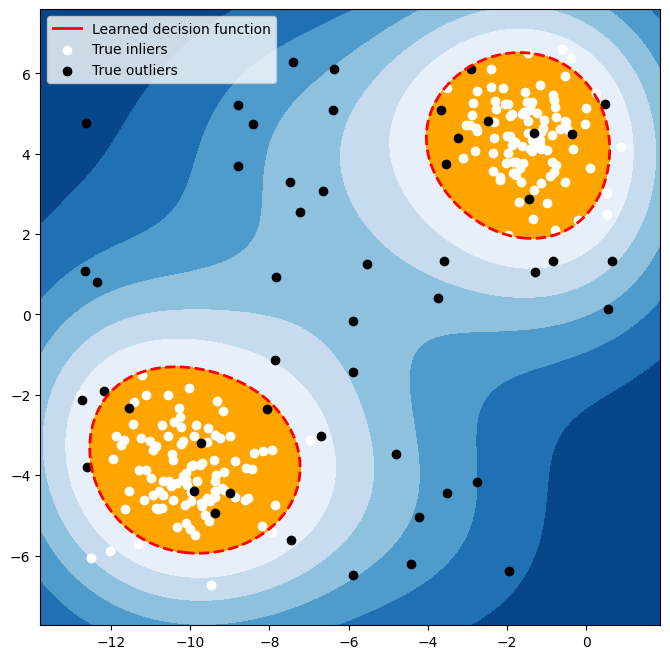

In [ ]:
# Generate data
from sklearn.datasets import make_blobs

inliers, _ = make_blobs(n_samples=200, centers=2, random_state=1)
outliers = np.random.rand(50, 2)
outliers = np.min(inliers, axis=0) + (np.max(inliers, axis=0) - np.min(inliers, axis=0)) * outliers

X = np.vstack((inliers, outliers))
ground_truth = np.ones(len(X), dtype=int)
ground_truth[-len(outliers):] = 0

from sklearn.svm import OneClassSVM
from sklearn.covariance import EllipticEnvelope
from sklearn.ensemble import IsolationForest

# Unsupervised learning
estimator = OneClassSVM(nu=0.4, kernel="rbf", gamma=0.1)
# clf = EllipticEnvelope(contamination=.1)
# clf = IsolationForest(max_samples=100)
estimator.fit(X)

plot_outlier_detector(estimator, X, ground_truth)

##**Ensembling for robustness**
Bias-variance decomposition

**Theorem.** For the squared error loss, the bias-variance decomposition of the expected generalization error at X=x is

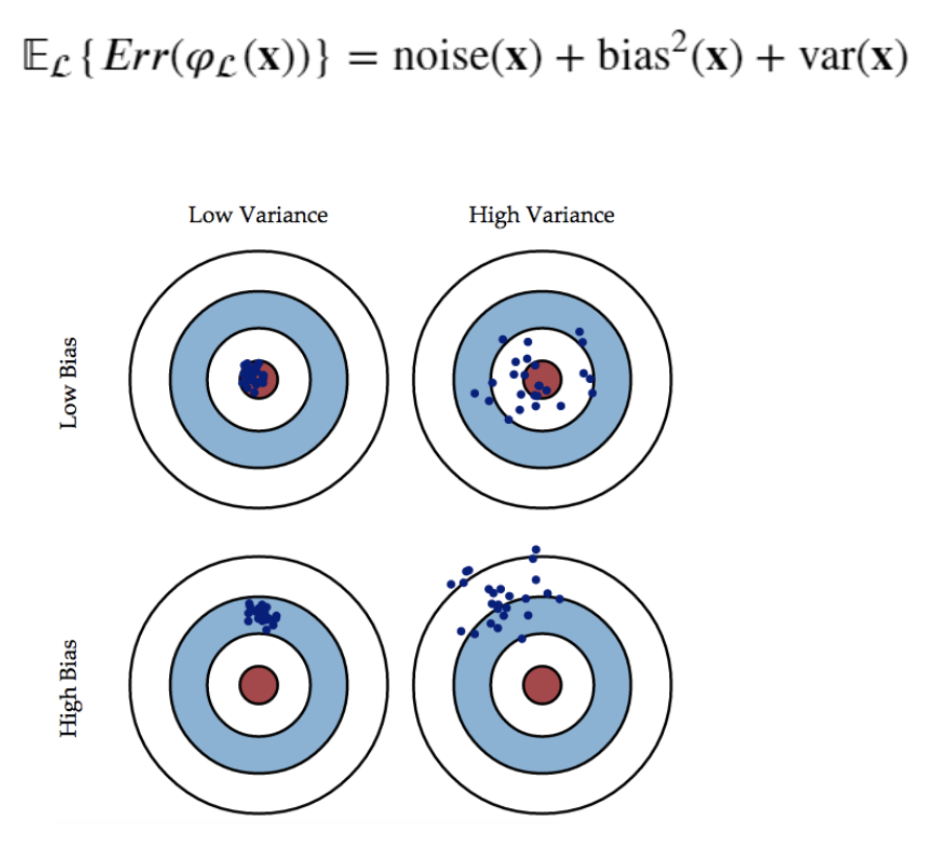
**Variance and robustness**
Low variance implies robustness to outliers

*   Low variance implies robustness to outliers
*   High variance implies sensitivity to data pecularities

**Ensembling reduces variance**

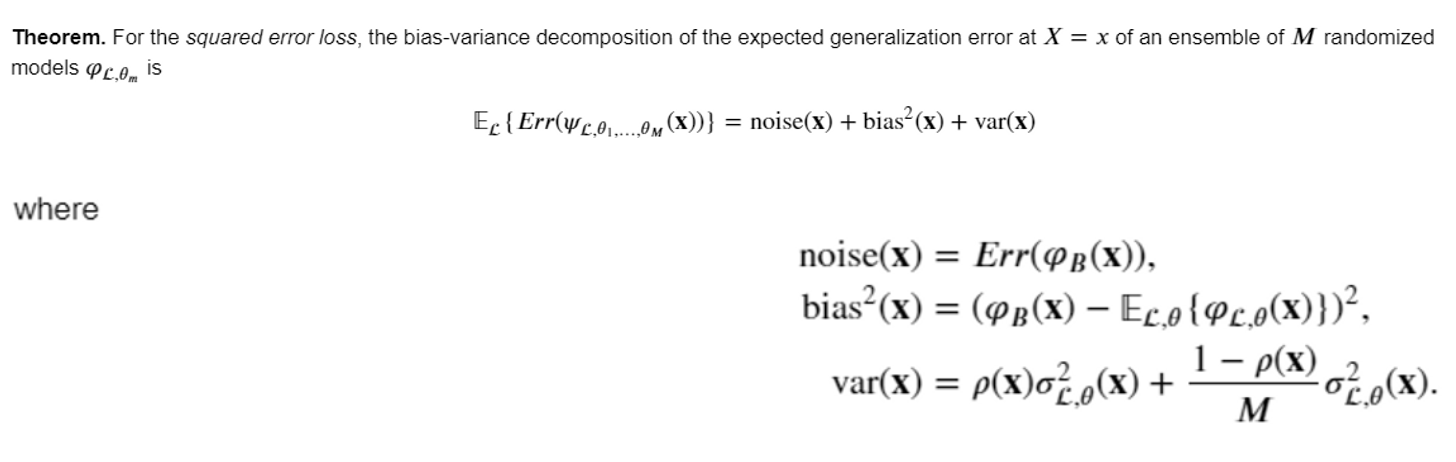

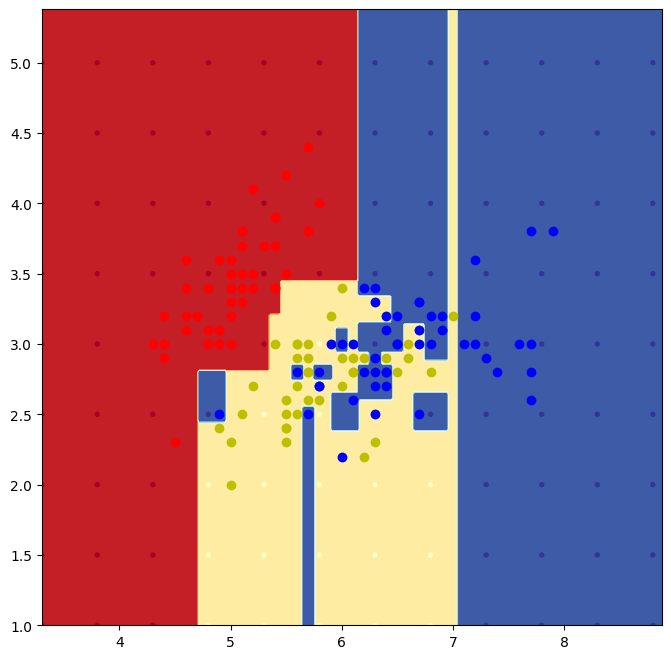

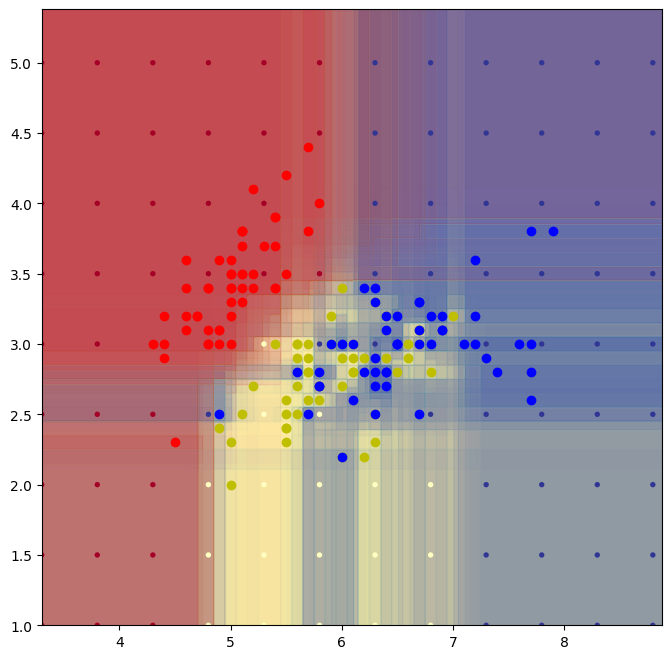

In [ ]:
# Load data
from sklearn.datasets import load_iris

iris = load_iris()
X = iris.data[:, [0, 1]]
y = iris.target

from sklearn.tree import DecisionTreeClassifier
clf = DecisionTreeClassifier().fit(X, y)
plot_surface(clf, X, y)

from sklearn.ensemble import RandomForestClassifier
clf = RandomForestClassifier(n_estimators=100).fit(X, y)
plot_surface(clf, X, y)

**Robust learning**



*   Most methods minimize the mean squared error

$$\frac{1}{N}\sum_i (y_i-\varphi(x_i))^2$$

*   By definition, squaring residuals gives emphasis to large residuals.

*   Outliers are thus very likely to have a significant effect.
*   A robust alternative is to minimize instead the mean absolute deviation

$$\frac{1}{N}\sum_i \vert y_i-\varphi(x_i)\vert$$

*   Large residuals are therefore given much less emphasis.






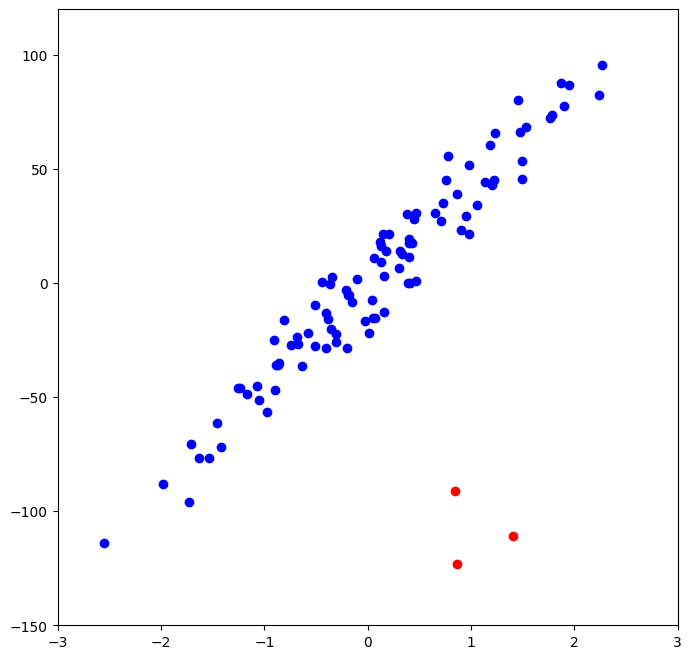

In [ ]:
# Generate data
from sklearn.datasets import make_regression

n_outliers = 3
X, y, coef = make_regression(n_samples=100, n_features=1, n_informative=1, noise=10,
                             coef=True, random_state=0)

np.random.seed(1)
X[-n_outliers:] = 1 + 0.25 * np.random.normal(size=(n_outliers, 1))
y[-n_outliers:] = -100 + 10 * np.random.normal(size=n_outliers)

plt.scatter(X[:-n_outliers], y[:-n_outliers], color="b")
plt.scatter(X[-n_outliers:], y[-n_outliers:], color="r")
plt.xlim(-3, 3)
plt.ylim(-150, 120)
plt.show()

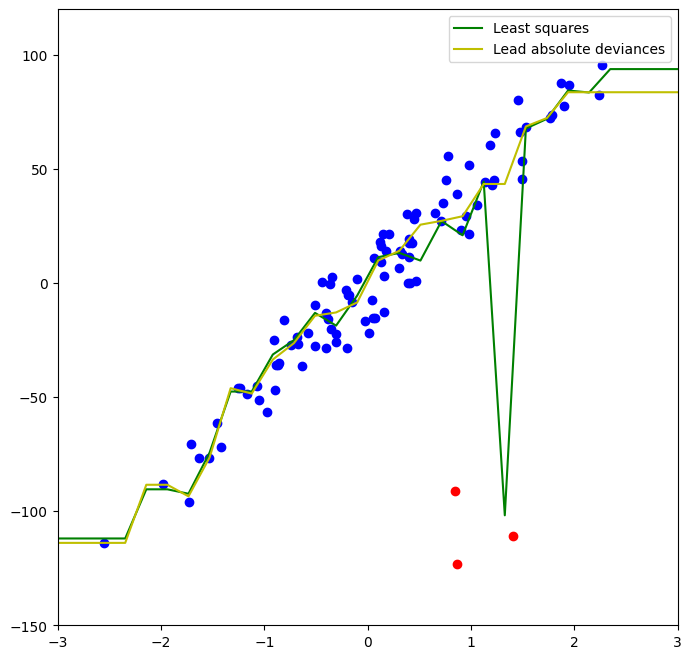

In [ ]:
# Fit with least squares vs. least absolute deviances
from sklearn.ensemble import GradientBoostingRegressor

clf_ls = GradientBoostingRegressor(loss="squared_error")
clf_lad = GradientBoostingRegressor(loss="absolute_error")
clf_ls.fit(X, y)
clf_lad.fit(X, y)

# Plot
X_test = np.linspace(-5, 5).reshape(-1, 1)
plt.scatter(X[:-n_outliers], y[:-n_outliers], color="b")
plt.scatter(X[-n_outliers:], y[-n_outliers:], color="r")
plt.plot(X_test, clf_ls.predict(X_test), "g", label="Least squares")
plt.plot(X_test, clf_lad.predict(X_test), "y", label="Lead absolute deviances")
plt.xlim(-3, 3)
plt.ylim(-150, 120)
plt.legend()
plt.show()

##**Robust scaling**



*   Standardization of a dataset is a common requirement for many machine learning estimators.

*   Typically this is done by removing the mean and scaling to unit variance.
*   For similar reasons as before, outliers can influence the sample mean / variance in a negative way.

*   In such cases, the median and the interquartile range often give better results.



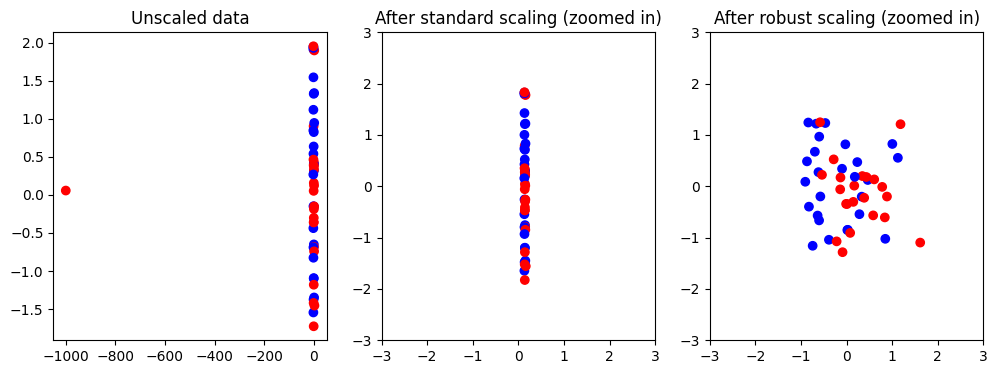

In [ ]:
# Generate data
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

X, y = make_blobs(n_samples=100, centers=[(0, 0), (-1, 0)], random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=0)
X_train[0, 0] = -1000  # a fairly large outlier

# Scale data
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import RobustScaler

standard_scaler = StandardScaler()
Xtr_s = standard_scaler.fit_transform(X_train)
Xte_s = standard_scaler.transform(X_test)

robust_scaler = RobustScaler()
Xtr_r = robust_scaler.fit_transform(X_train)
Xte_r = robust_scaler.transform(X_test)
# Plot data
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].scatter(X_train[:, 0], X_train[:, 1], color=np.where(y_train == 0, 'r', 'b'))
ax[1].scatter(Xtr_s[:, 0], Xtr_s[:, 1], color=np.where(y_train == 0, 'r', 'b'))
ax[2].scatter(Xtr_r[:, 0], Xtr_r[:, 1], color=np.where(y_train == 0, 'r', 'b'))
ax[0].set_title("Unscaled data")
ax[1].set_title("After standard scaling (zoomed in)")
ax[2].set_title("After robust scaling (zoomed in)")

# for the scaled data, we zoom in to the data center (outlier can't be seen!)
for a in ax[1:]:
    a.set_xlim(-3, 3)
    a.set_ylim(-3, 3)

plt.show()

In [ ]:
# Classify using kNN
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier()
knn.fit(Xtr_s, y_train)
acc_s = knn.score(Xte_s, y_test)
print("Test set accuracy using standard scaler: %.3f" % acc_s)

knn.fit(Xtr_r, y_train)
acc_r = knn.score(Xte_r, y_test)
print("Test set accuracy using robust scaler:   %.3f" % acc_r)

Test set accuracy using standard scaler: 0.460
Test set accuracy using robust scaler:   0.680


##**Calibration**

*   In classification, you often want to predict not only the class label, but also the associated probability.

*   However, not all classifiers provide well-calibrated probabilities.
*   Thus, a separate calibration of predicted probabilities is often desirable as a postprocessing

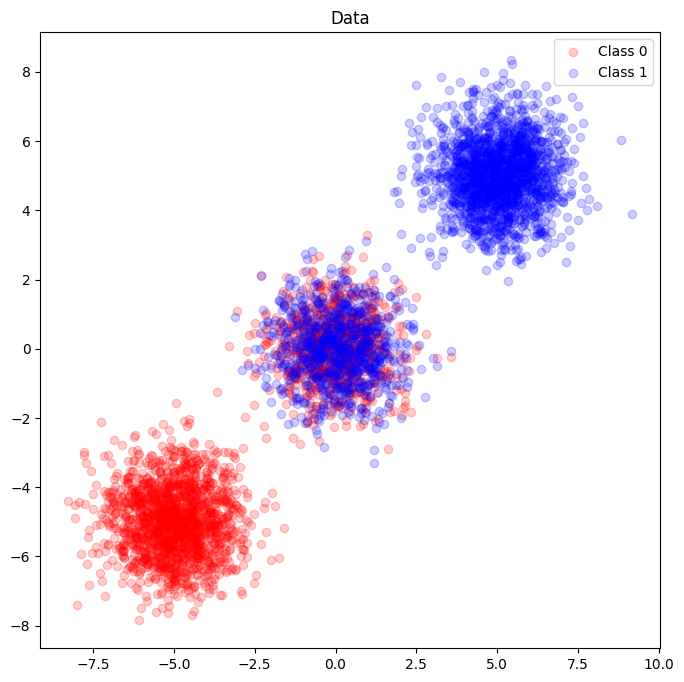

In [ ]:
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

# Generate 3 blobs with 2 classes where the second blob contains
# half positive samples and half negative samples. Probability in this
# blob is therefore 0.5.
X, y = make_blobs(n_samples=10000, n_features=2, cluster_std=1.0,
                  centers=[(-5, -5), (0, 0), (5, 5)], shuffle=False)
y[:len(X) // 2] = 0
y[len(X) // 2:] = 1
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=42)

# Plot
for this_y, color in zip([0, 1], ["r", "b"]):
    this_X = X_train[y_train == this_y]
    plt.scatter(this_X[:, 0], this_X[:, 1], c=color, alpha=0.2, label="Class %s" % this_y)
plt.legend(loc="best")
plt.title("Data")
plt.show()

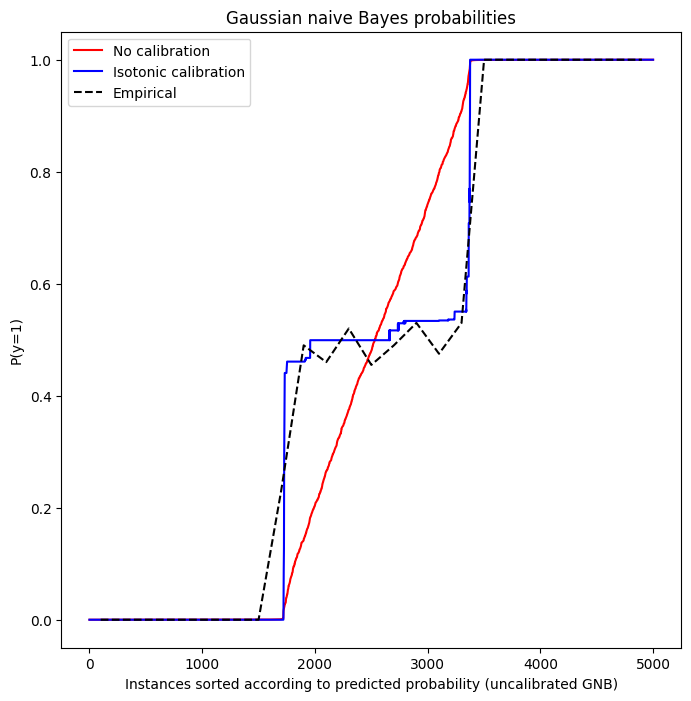

In [ ]:
from sklearn.naive_bayes import GaussianNB
from sklearn.calibration import CalibratedClassifierCV

# Without calibration
clf = GaussianNB()
clf.fit(X_train, y_train)  # GaussianNB itself does not support sample-weights
prob_pos_clf = clf.predict_proba(X_test)[:, 1]

# With isotonic calibration
clf_isotonic = CalibratedClassifierCV(clf, cv=2, method='isotonic')
clf_isotonic.fit(X_train, y_train)
prob_pos_isotonic = clf_isotonic.predict_proba(X_test)[:, 1]

# Plot
order = np.lexsort((prob_pos_clf, ))
plt.plot(prob_pos_clf[order], 'r', label='No calibration')
plt.plot(prob_pos_isotonic[order], 'b', label='Isotonic calibration')
plt.plot(np.linspace(0, y_test.size, 51)[1::2], y_test[order].reshape(25, -1).mean(1), 'k--', label=r'Empirical')

plt.xlabel("Instances sorted according to predicted probability "
           "(uncalibrated GNB)")
plt.ylabel("P(y=1)")
plt.legend(loc="upper left")
plt.title("Gaussian naive Bayes probabilities")
plt.ylim([-0.05, 1.05])
plt.show()